In [ ]:
import networkx as nx
import polars as pl
Edges = pl.read_csv("/home/alberto/LPSim/traffic_phase_transition/data/carto/BOS/edges.csv")
Dt = 15
MinutesInDay = 24*60
IntDtMinutesArray = [i for i in range(0, MinutesInDay, Dt)] 
for t in IntDtMinutesArray:
    Edges[f"trafficked_{t}"] = pl.Series("", [False for _ in range(Edges.shape[0])])

In [ ]:
p = 0.5
import numpy as np
# Function to update trafficked_{t} column
Edges.group_by("u").agg([pl.col("v") ])
def update_trafficked(df, p):
    # Iterate over each index
    
    for idx in df['index']:
        # Select rows where pl.col('u') of such index is pl.col('v') of those rows
        condition = df['v'] == df['u'][idx]
        selected_rows = df.filter(condition)
        # Generate random numbers
        random_numbers = np.random.uniform(0, 1, len(selected_rows))
        
        # Update trafficked_{t} column
        for i, row in selected_rows.iterrows():
            if random_numbers[i] > p:
                df = df.with_columns(
                    pl.when(pl.col('index') == row['index'])
                    .then(pl.col('trafficked_{t}') | True)
                    .otherwise(pl.col('trafficked_{t}'))
                    .alias('trafficked_{t}')
                )
    return df


osmid,x,y,ref,highway,index
i64,f64,f64,str,str,i64
61816807,-70.844629,41.995558,null,null,0
61817002,-70.843934,41.996081,null,null,1
61817016,-70.866671,41.973369,null,null,2
61817409,-70.84401,41.995529,null,null,3
61817412,-70.872564,41.993312,null,null,4
…,…,…,…,…,…
10281222830,-71.446432,42.763661,null,null,23462
10281222831,-71.446355,42.763559,null,null,23463
10281222833,-71.44625,42.763443,null,null,23464


In [1]:
import polars as pl
pl.read_parquet("/home/alberto/LPSim/LivingCity/berkeley_2018/BOS/Output/Plots/0.216/R_330_UCI_0.216_traffic.parquet")

uniqueid,u,v,length,speed_mph,lanes,capacity,speed_kmh,speed_kmh_right,time_entering_road,flux_95,speed_kmh_95,speed_kmh_28,flux_28,speed_kmh_29,flux_29,speed_kmh_30,flux_30,speed_kmh_31,flux_31,speed_kmh_32,flux_32,speed_kmh_33,flux_33,speed_kmh_34,flux_34,speed_kmh_35,flux_35,speed_kmh_36,flux_36,speed_kmh_37,flux_37,speed_kmh_38,flux_38,speed_kmh_39,flux_39,speed_kmh_40,…,flux_77,speed_kmh_78,flux_78,speed_kmh_79,flux_79,speed_kmh_80,flux_80,speed_kmh_81,flux_81,speed_kmh_82,flux_82,speed_kmh_83,flux_83,speed_kmh_84,flux_84,speed_kmh_85,flux_85,speed_kmh_86,flux_86,speed_kmh_87,flux_87,speed_kmh_88,flux_88,speed_kmh_89,flux_89,speed_kmh_90,flux_90,speed_kmh_91,flux_91,speed_kmh_92,flux_92,speed_kmh_93,flux_93,speed_kmh_94,flux_94,speed_kmh_95_right,flux_95_right
i64,i64,i64,f64,i64,i64,i64,f64,f64,f64,i32,i32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,…,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32,f64,u32
34197,14579,7227,140.9,30,2,4800,48.0,48.0,26089.495028,0,0,35.970689,77,31.408047,72,27.325698,66,27.943023,91,28.846861,60,37.465426,30,35.781897,18,43.530326,15,45.062956,12,50.219013,8,44.302579,8,32.488867,8,40.562161,…,6,40.209103,15,38.479289,9,45.348313,9,50.174239,3,36.910911,10,42.675833,4,54.516287,5,42.780628,7,43.21183,5,39.4371,3,39.43579,4,51.408952,3,45.176789,8,null,null,3.398009,1,44.704528,1,42.776237,1,null,null
5057,2060,2969,517.8,25,1,2800,40.0,40.0,25204.580227,0,0,null,null,null,null,38.031515,1,null,null,41.878096,2,null,null,null,null,38.445145,1,37.697266,1,null,null,null,null,null,null,56.262933,…,null,35.801479,2,41.113034,1,40.573634,3,null,null,44.439613,1,null,null,39.796779,1,37.638049,2,42.621965,2,39.636524,1,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
7238,2964,2959,23.7,25,1,2800,40.0,40.0,27791.135251,0,0,48.375134,16,46.454794,20,44.682826,15,41.527366,13,50.302595,10,52.368293,8,52.207411,2,50.540911,3,59.073994,8,55.315289,7,63.242416,4,74.79021,1,48.035098,…,6,45.410778,5,null,null,37.702316,2,39.562581,2,45.592243,4,null,null,46.529712,3,null,null,46.519391,5,44.905192,2,42.536535,4,73.83316,1,51.849185,3,41.224216,3,43.330192,3,39.239319,2,null,null,null,null
12616,5258,5458,450.2,27,1,2400,43.2,43.2,25777.506453,0,0,37.236129,292,31.808395,311,28.961463,342,27.250378,385,26.841047,382,23.545649,205,22.394254,177,18.535323,138,21.916694,149,16.470111,97,13.089303,83,6.721877,75,4.317465,…,118,2.663258,114,2.248901,108,2.254423,107,2.772891,106,3.30391,105,2.456721,97,3.172107,100,2.799219,98,4.189023,98,2.717448,92,3.18233,89,3.132067,80,4.022114,75,3.480583,62,5.335969,55,5.46755,43,9.341397,16,1.091564,4
13963,5805,5807,43.1,20,2,2400,32.0,32.0,25264.3,0,0,null,null,39.836516,1,39.521397,1,28.562811,1,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
3265,1343,1220,38.8,25,1,2800,40.0,40.0,26799.266543,0,0,31.67239,12,25.865972,14,29.913303,12,31.568703,4,24.370399,5,21.057441,3,25.145703,2,43.625905,2,45.016992,1,44.100161,1,40.626369,2,null,null,37.059849,…,1,null,null,43.045082,1,null,null,null,null,null,null,null,null,null,null,43.779734,1,null,null,null,null,41.361538,2,35.054221,1,41.875677,1,null,null,null,null,null,null,null,null,null,null
1989,806,858,351.4,30,1,3200,48.0,48.0,29363.523675,0,0,50.061456,111,44.495842,155,42.199882,168,40.667228,180,41.799615,112,45.00678,55,51.200205,37,57.364517,28,58.435528,26,61.427684,18,58.037239,16,58.787502,18,61.809621,…,52,50.86573,54,48.206738,48,48.47049,57,46.155822,58,50.1

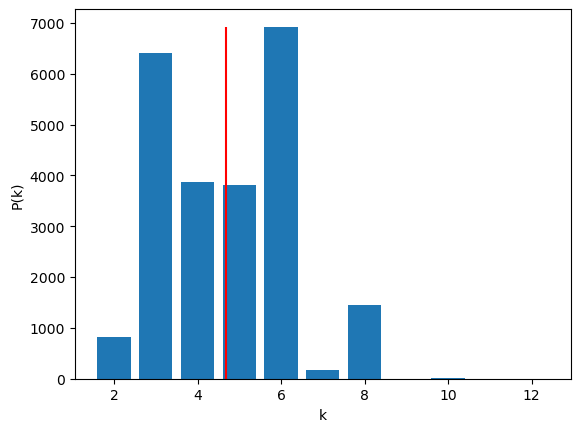

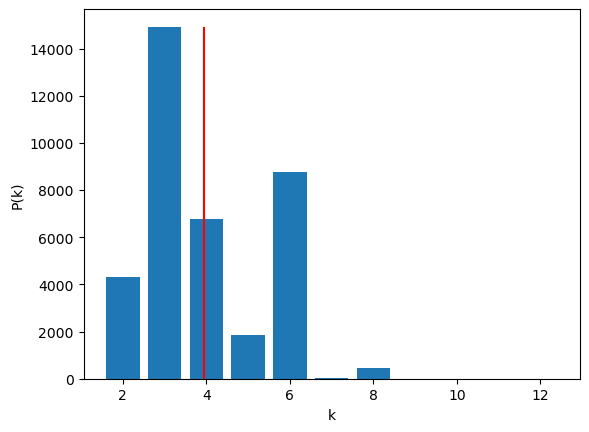

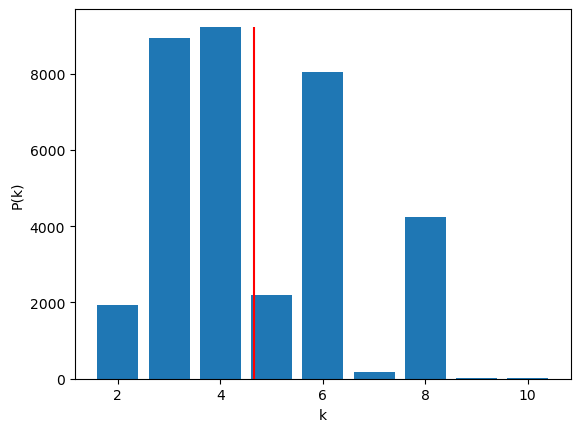

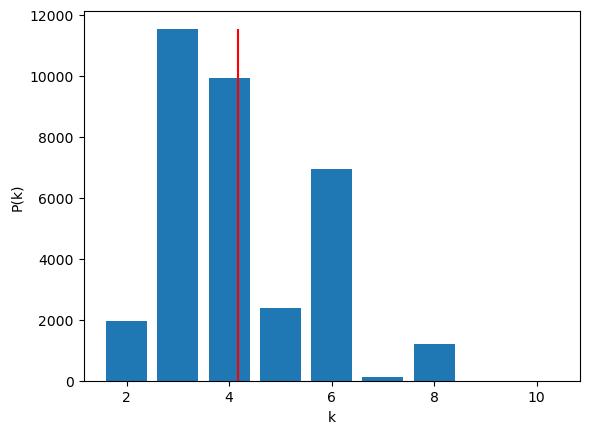

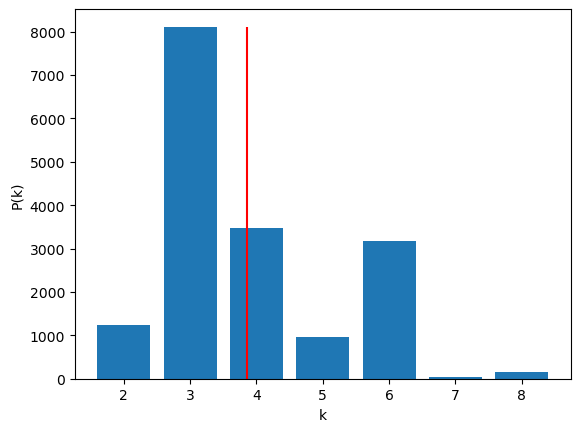

In [3]:
import osmnx as ox
import matplotlib.pyplot as plt
import numpy as np
Names = ["BOS","LIS","LAX","SFO","RIO"]
for name in Names:
    G = ox.load_graphml(f"/home/alberto/LPSim/traffic_phase_transition/data/carto/{name}/{name}_new_tertiary_simplified.graphml")
    degree_sequence = sorted([d for n, d in G.degree()], reverse=True)
    av = np.mean(degree_sequence)
    fig,ax = plt.subplots()
    ax.bar(*np.unique(degree_sequence, return_counts=True))
    ax.vlines(av, 0, max(np.unique(degree_sequence, return_counts=True)[1]), color='red')
    ax.set_xlabel('k')
    ax.set_ylabel('P(k)')
    plt.show()
    plt.savefig(f"/home/alberto/LPSim/traffic_phase_transition/data/carto/{name}/{name}_degree_distribution.png")
    plt.close()

In [4]:
G.is_directed()

True